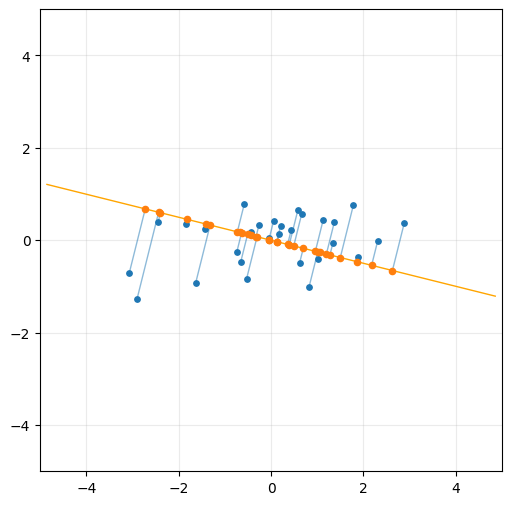

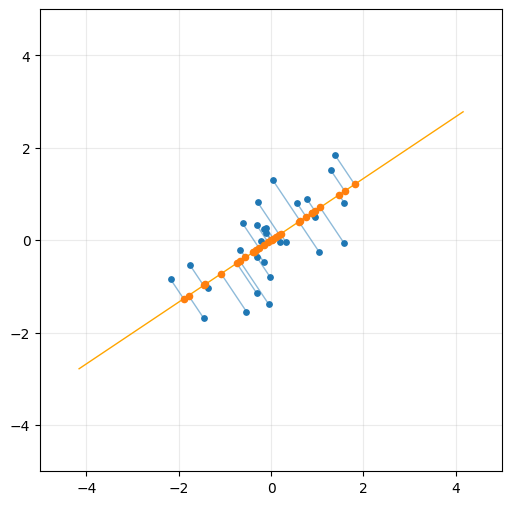

Sample canonical correlation (1st component): 1.000


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cross_decomposition import CCA

# -----------------------
# Data generation (two 2D clouds sharing a latent 1D signal)
# -----------------------
rng = np.random.default_rng(11)
n = 30

# latent 1D signal (shared)
t = rng.normal(size=(n, 1))

# Mixing matrices for each view (make them different & oblique)
A_x = np.array([[1.6, 0.6],
                [0.1, 0.9]])  # 2x2, applied to [t, noise]
A_y = np.array([[1.0, -0.5],
                [0.8,  0.7]])

# Build each cloud: mix latent + independent noise
noise_x = rng.normal(scale=0.7, size=(n, 1))
noise_y = rng.normal(scale=0.7, size=(n, 1))

X = np.hstack([t, noise_x]) @ A_x.T
Y = np.hstack([t, noise_y]) @ A_y.T

# Center each cloud exactly
X = X - X.mean(axis=0, keepdims=True)
Y = Y - Y.mean(axis=0, keepdims=True)
mu_x = X.mean(axis=0)
mu_y = Y.mean(axis=0)

# -----------------------
# CCA (1 component)
# -----------------------
cca = CCA(n_components=1)
cca.fit(X, Y)

# Weight vectors (directions) in the original spaces
w_x = cca.x_weights_[:, 0]    # shape (2,)
w_y = cca.y_weights_[:, 0]    # shape (2,)

# Normalize to unit vectors for clean geometry
u_x = w_x / (np.linalg.norm(w_x) + 1e-12)
u_y = w_y / (np.linalg.norm(w_y) + 1e-12)

# Helper: orthogonal projection of a point onto a line through mean with direction u
def proj_on_line(x, mu, u):
    return mu + np.dot(x - mu, u) * u

X_proj = np.array([proj_on_line(x, mu_x, u_x) for x in X])
Y_proj = np.array([proj_on_line(y, mu_y, u_y) for y in Y])

# -----------------------
# Plotting helpers (cosmetics as in your code)
# -----------------------
def plot_cloud_with_line_and_projections(P, P_proj, mu, u, title, fname):
    plt.figure(figsize=(6, 6))
    plt.scatter(P[:, 0], P[:, 1], s=15, label="points", zorder=3)

    # draw long line segment along direction u through mean
    L = 5
    a, b = mu - L * u, mu + L * u
    plt.plot([a[0], b[0]], [a[1], b[1]], linewidth=1, label="canonical line", zorder=2, color='orange')

    # projection segments
    for p, pp in zip(P, P_proj):
        plt.plot([p[0], pp[0]], [p[1], pp[1]], linewidth=1, color='C0', alpha=0.5)

    # projected points
    plt.scatter(P_proj[:, 0], P_proj[:, 1], s=20, marker='o', label="projection", zorder=4)

    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid(True, alpha=0.25)
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    # plt.legend(loc="best")
    plt.savefig(fname, dpi=300)
    plt.show()

# -----------------------
# Make the two figures
# -----------------------
plot_cloud_with_line_and_projections(
    X, X_proj, mu_x, u_x,
    title="CCA — View X: projections onto canonical line",
    fname="cca-view-X.png"
)

plot_cloud_with_line_and_projections(
    Y, Y_proj, mu_y, u_y,
    title="CCA — View Y: projections onto canonical line",
    fname="cca-view-Y.png"
)

# Optional: show sample correlation of the 1D canonical variates
x_scores, y_scores = cca.transform(X, Y)  # n x 1 each
corr = np.corrcoef(x_scores[:, 0], y_scores[:, 0])[0, 1]
print(f"Sample canonical correlation (1st component): {corr:.3f}")
